# 09 — Formal mixed-opponent candidate benchmark

This notebook performs a locked evaluation of seven candidate agents against `external_feature_is_everything + external_deep_learning_killer + rule_based_agent`. Each candidate occupies the first agent slot and is evaluated without training in the classic scenario. The later engine-aligned extension adds `engine_aligned_0000` and `frozen_engine_aligned_0200` without changing the original pipeline or seeds.

## Locked protocol

The suite uses five previously unused seeds (`64001–64005`) and 30 rounds per seed: 150 rounds per candidate and 1,050 rounds total after the two-candidate extension. Opponent order, scenario, round count, seats, and seeds are unchanged. The original five candidates retain their original raw results and provenance sidecars; only the two missing engine-aligned candidates are executed. Raw results are never overwritten, and every result has a provenance sidecar containing its command, protocol, and SHA-256.

In [1]:
from __future__ import annotations

import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

def find_project_root(start=None):
    candidate = Path(start or Path.cwd()).resolve()
    for directory in (candidate, *candidate.parents):
        if (directory / 'main.py').is_file() and (directory / 'agent_code').is_dir():
            return directory
    raise FileNotFoundError('Could not find the project root containing main.py and agent_code/')

ROOT = find_project_root()
RESULT_DIR = ROOT / 'results/notebook09_formal_mixed_benchmark'
REPORT = RESULT_DIR / 'report.json'
CANDIDATES = ['dueling_hunt_center_04', 'hunt_center_04_mix_0800', 'dueling_ddqn_agent',
              'frozen_sarsa_best', 'frozen_linear_q_final', 'engine_aligned_0000',
              'frozen_engine_aligned_0200']
OPPONENTS = ['external_feature_is_everything', 'external_deep_learning_killer', 'rule_based_agent']
SEEDS = [64001, 64002, 64003, 64004, 64005]
ROUNDS_PER_SEED = 30
RUN_SUITE = False  # Set True only when the report is absent; the runner safely resumes matching raw files.
print(f'{len(CANDIDATES)} candidates × {len(SEEDS)} seeds × {ROUNDS_PER_SEED} rounds = {len(CANDIDATES)*len(SEEDS)*ROUNDS_PER_SEED}')

7 candidates × 5 seeds × 30 rounds = 1050


In [2]:
if RUN_SUITE:
    subprocess.run([sys.executable, 'evaluation/run_notebook09_formal_suite.py',
                    '--rounds', str(ROUNDS_PER_SEED), '--seeds', *map(str, SEEDS)],
                   cwd=ROOT, check=True)
assert REPORT.exists(), 'Run the locked suite before analysis'
payload = json.loads(REPORT.read_text())
expected = {'experiment': 'notebook09_formal_mixed_benchmark', 'scenario': 'classic',
            'rounds_per_seed': ROUNDS_PER_SEED, 'seeds': SEEDS,
            'lineup_order': ['<candidate>', *OPPONENTS], 'candidates': CANDIDATES,
            'opponents': OPPONENTS, 'training': False}
assert payload['protocol'] == expected, 'Report protocol drift'
assert len(payload['runs']) == len(CANDIDATES) * len(SEEDS)
print('Loaded locked report:', REPORT.relative_to(ROOT))

Loaded locked report: results/notebook09_formal_mixed_benchmark/report.json


## Aggregate and seed-level results

Official mean score is the primary metric. Win rate, mean rank, score margin, resources, kills, suicides, invalid actions, survival, and latency are supporting diagnostics. Lower mean rank, suicides, invalid actions, and latency are better.

In [3]:
aggregate_rows, seed_rows = [], []
for block in payload['comparisons']:
    aggregate_rows.append(block['aggregate'])
    for seed_block in block['by_seed']:
        seed_rows.append({'seed': seed_block['seed'], **seed_block['candidate']})
aggregate = pd.DataFrame(aggregate_rows).set_index('agent')
per_seed = pd.DataFrame(seed_rows)
aggregate = aggregate.loc[CANDIDATES].sort_values('mean_score', ascending=False)
columns = ['rounds', 'mean_score', 'win_rate', 'mean_rank', 'mean_score_margin',
           'coins_per_round', 'crates_per_round', 'kills_per_round',
           'suicides_per_round', 'invalid_per_round', 'survival_rate', 'mean_action_ms']
aggregate[columns].to_csv(RESULT_DIR / 'candidate_aggregate.csv')
per_seed.to_csv(RESULT_DIR / 'candidate_by_seed.csv', index=False)
display(aggregate[columns].round(3))

,rounds,mean_score,win_rate,mean_rank,mean_score_margin,coins_per_round,crates_per_round,kills_per_round,suicides_per_round,invalid_per_round,survival_rate,mean_action_ms
agent,,,,,,,,,,,,
frozen_engine_aligned_0200,150,3.360,0.307,2.340,0.184,2.027,26.200,0.267,0.133,8.100,0.647,2.539
dueling_ddqn_agent,150,2.907,0.253,2.347,-0.153,1.840,22.900,0.213,0.173,3.267,0.667,2.513
hunt_center_04_mix_0800,150,2.860,0.253,2.467,-0.424,1.927,25.833,0.187,0.140,8.407,0.593,2.609
dueling_hunt_center_04,150,2.820,0.260,2.367,-0.182,1.853,23.247,0.193,0.193,3.173,0.713,3.611
engine_aligned_0000,150,2.527,0.233,2.520,-0.498,1.693,22.373,0.167,0.147,3.260,0.760,2.352
frozen_linear_q_final,150,2.060,0.160,2.667,-1.213,1.993,24.467,0.013,0.253,0.173,0.533,1.288
frozen_sarsa_best,150,1.820,0.147,2.760,-1.253,1.620,18.287,0.040,0.313,0.440,0.633,1.126


## Paired seed-cluster bootstrap

Every candidate uses the same five seed streams. To avoid treating the 30 rounds within a seed as fully independent, uncertainty is estimated by resampling the five seed-level mean-score differences as clusters. The reference is `dueling_hunt_center_04`; 20,000 bootstrap resamples produce the reported 95% confidence intervals.

In [4]:
REFERENCE = 'dueling_hunt_center_04'
score_matrix = per_seed.pivot(index='seed', columns='agent', values='mean_score').loc[SEEDS, CANDIDATES]
rng = np.random.default_rng(20260916)
bootstrap_rows = []
for candidate in CANDIDATES:
    differences = (score_matrix[candidate] - score_matrix[REFERENCE]).to_numpy()
    indices = rng.integers(0, len(SEEDS), size=(20_000, len(SEEDS)))
    boot = differences[indices].mean(axis=1)
    bootstrap_rows.append({
        'candidate': candidate,
        'mean_score': aggregate.loc[candidate, 'mean_score'],
        'gain_vs_reference': differences.mean(),
        'ci95_low': np.quantile(boot, .025),
        'ci95_high': np.quantile(boot, .975),
        'positive_seed_fraction': np.mean(differences > 0),
    })
bootstrap = pd.DataFrame(bootstrap_rows).set_index('candidate').sort_values('mean_score', ascending=False)
bootstrap.to_csv(RESULT_DIR / 'paired_seed_bootstrap.csv')
display(score_matrix.round(3))
display(bootstrap.round(3))

# Direct paired comparison requested for the two engine-aligned checkpoints.
engine_pair_differences = (score_matrix['frozen_engine_aligned_0200'] - score_matrix['engine_aligned_0000']).to_numpy()
pair_rng = np.random.default_rng(20260917)
pair_indices = pair_rng.integers(0, len(SEEDS), size=(20_000, len(SEEDS)))
pair_boot = engine_pair_differences[pair_indices].mean(axis=1)
engine_pair = {
    'comparison': 'frozen_engine_aligned_0200 minus engine_aligned_0000',
    'seed_differences': engine_pair_differences.tolist(),
    'mean_difference': float(engine_pair_differences.mean()),
    'ci95': [float(np.quantile(pair_boot, .025)), float(np.quantile(pair_boot, .975))],
    'positive_seed_fraction': float(np.mean(engine_pair_differences > 0)),
    'bootstrap_samples': 20_000, 'bootstrap_seed': 20260917,
}
(RESULT_DIR / 'engine_aligned_pair_bootstrap.json').write_text(json.dumps(engine_pair, indent=2) + '\n')
display(Markdown(
    f"**Direct engine-aligned pair:** `0200 − 0000 = {engine_pair['mean_difference']:+.3f}` "
    f"score/round, 95% seed-cluster bootstrap CI "
    f"`[{engine_pair['ci95'][0]:.3f}, {engine_pair['ci95'][1]:.3f}]`; "
    f"positive in `{int(engine_pair['positive_seed_fraction'] * len(SEEDS))}/{len(SEEDS)}` seeds."
))

agent,dueling_hunt_center_04,hunt_center_04_mix_0800,dueling_ddqn_agent,frozen_sarsa_best,frozen_linear_q_final,engine_aligned_0000,frozen_engine_aligned_0200
seed,,,,,,,
64001,2.400,2.933,3.133,1.967,1.600,2.833,3.433
64002,2.233,2.067,3.133,1.833,2.267,2.500,3.167
64003,3.833,3.367,2.800,2.033,2.500,2.233,2.400
64004,2.700,2.433,2.733,1.833,2.033,2.200,3.867
64005,2.933,3.500,2.733,1.433,1.900,2.867,3.933


,mean_score,gain_vs_reference,ci95_low,ci95_high,positive_seed_fraction
candidate,,,,,
frozen_engine_aligned_0200,3.360,0.540,-0.460,1.087,0.8
dueling_ddqn_agent,2.907,0.087,-0.513,0.660,0.6
hunt_center_04_mix_0800,2.860,0.040,-0.327,0.407,0.4
dueling_hunt_center_04,2.820,0.000,0.000,0.000,0.0
engine_aligned_0000,2.527,-0.293,-0.987,0.267,0.4
frozen_linear_q_final,2.060,-0.760,-1.140,-0.320,0.2
frozen_sarsa_best,1.820,-1.000,-1.493,-0.507,0.0


**Direct engine-aligned pair:** `0200 − 0000 = +0.833` score/round, 95% seed-cluster bootstrap CI `[0.433, 1.267]`; positive in `5/5` seeds.

## Diagnostic plots

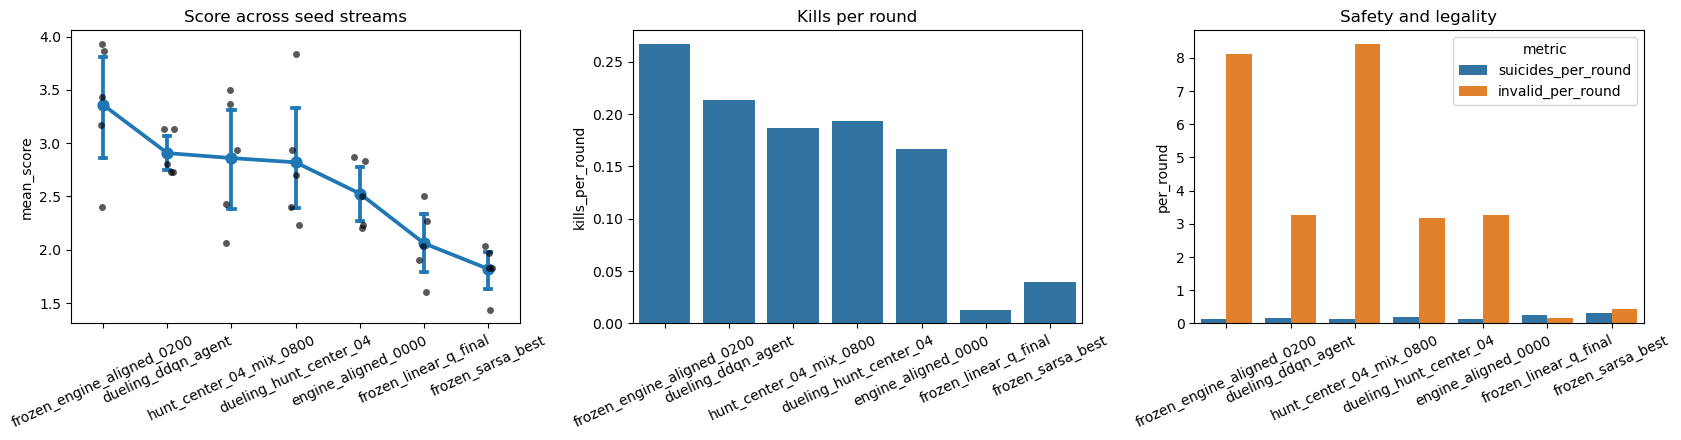

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
order = aggregate.index.tolist()
sns.pointplot(data=per_seed, x='agent', y='mean_score', order=order, errorbar=('ci', 95), capsize=.1, ax=axes[0])
sns.stripplot(data=per_seed, x='agent', y='mean_score', order=order, color='black', alpha=.65, ax=axes[0])
sns.barplot(data=aggregate.reset_index(), x='agent', y='kills_per_round', order=order, errorbar=None, ax=axes[1])
safety = aggregate.reset_index().melt(id_vars='agent', value_vars=['suicides_per_round', 'invalid_per_round'],
                                      var_name='metric', value_name='per_round')
sns.barplot(data=safety, x='agent', y='per_round', hue='metric', order=order, errorbar=None, ax=axes[2])
for ax, title in zip(axes, ['Score across seed streams', 'Kills per round', 'Safety and legality']):
    ax.set_title(title); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

## Formal decision report

In [6]:
winner = aggregate.index[0]
best = aggregate.loc[winner]
reference_row = bootstrap.loc[winner]
decision = {
    'winner': winner, 'mean_score': float(best.mean_score), 'win_rate': float(best.win_rate),
    'mean_rank': float(best.mean_rank), 'kills_per_round': float(best.kills_per_round),
    'suicides_per_round': float(best.suicides_per_round),
    'invalid_per_round': float(best.invalid_per_round),
    'survival_rate': float(best.survival_rate), 'mean_action_ms': float(best.mean_action_ms),
    'gain_vs_dueling_hunt_center_04': float(reference_row.gain_vs_reference),
    'paired_seed_ci95': [float(reference_row.ci95_low), float(reference_row.ci95_high)],
}
(RESULT_DIR / 'decision.json').write_text(json.dumps(decision, indent=2) + '\n')
display(Markdown(
    f"**Highest primary-metric point estimate:** `{winner}` with `{best.mean_score:.3f}` score/round, "
    f"`{best.win_rate:.3f}` win rate, `{best.kills_per_round:.3f}` kills/round, "
    f"`{best.suicides_per_round:.3f}` suicides/round, and `{best.invalid_per_round:.3f}` "
    f"invalid actions/round. Its paired seed-cluster score difference relative to "
    f"`dueling_hunt_center_04` is `{reference_row.gain_vs_reference:+.3f}` with 95% CI "
    f"`[{reference_row.ci95_low:.3f}, {reference_row.ci95_high:.3f}]`."
))

**Highest primary-metric point estimate:** `frozen_engine_aligned_0200` with `3.360` score/round, `0.307` win rate, `0.267` kills/round, `0.133` suicides/round, and `8.100` invalid actions/round. Its paired seed-cluster score difference relative to `dueling_hunt_center_04` is `+0.540` with 95% CI `[-0.460, 1.087]`.

## Interpretation and submission recommendation

| candidate | score | win rate | mean rank | score margin | kills | suicides | invalid | survival |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| `frozen_engine_aligned_0200` | **3.360** | **0.307** | **2.340** | **+0.184** | **0.267** | **0.133** | 8.100 | 0.647 |
| `dueling_ddqn_agent` | 2.907 | 0.253 | 2.347 | -0.153 | 0.213 | 0.173 | 3.267 | 0.667 |
| `hunt_center_04_mix_0800` | 2.860 | 0.253 | 2.467 | -0.424 | 0.187 | 0.140 | 8.407 | 0.593 |
| `dueling_hunt_center_04` | 2.820 | 0.260 | 2.367 | -0.182 | 0.193 | 0.193 | 3.173 | 0.713 |
| `engine_aligned_0000` | 2.527 | 0.233 | 2.520 | -0.498 | 0.167 | 0.147 | 3.260 | **0.760** |
| `frozen_linear_q_final` | 2.060 | 0.160 | 2.667 | -1.213 | 0.013 | 0.253 | 0.173 | 0.533 |
| `frozen_sarsa_best` | 1.820 | 0.147 | 2.760 | -1.253 | 0.040 | 0.313 | 0.440 | 0.633 |

`frozen_engine_aligned_0200` has the highest primary-metric point estimate at 3.360 score/round. Relative to `dueling_hunt_center_04`, its gain is +0.540 and appears in four of five seeds, but the paired seed-cluster 95% CI `[-0.460, 1.087]` still crosses zero. Thus this suite alone does not establish a reliable difference between those two independently developed policies.

The direct engine-aligned comparison is stronger: `0200` scores 3.360 versus 2.527 for `0000`, a paired gain of +0.833. All five seed differences are positive, and the direct 20,000-resample seed-cluster bootstrap interval is `[0.433, 1.267]`. Within this fixed opponent distribution, the correct-rule continuation improvement therefore replicates clearly over its exact starting checkpoint. `0200` also improves win rate, mean rank, kills and suicides, while `0000` retains higher survival and far fewer invalid actions.

The continued `hunt_center_04_mix_0800` checkpoint remains statistically indistinguishable from the original hunt-center policy by score (+0.040, 95% CI `[-0.327, 0.407]`). Both linear candidates are clearly weaker on score in this opponent distribution; their intervals relative to the reference are entirely negative.

**Updated recommendation:** retain `frozen_engine_aligned_0200` as the selected frozen best weight. Its advantage over unrelated `dueling_hunt_center_04` remains uncertain, but its advantage over the exact engine-aligned `0000` baseline is positive in every formal seed and has an entirely positive paired interval. The 8.100 invalid actions per round remain disclosed and are accepted under the separately documented same-turn contention decision.